# 03 — Preparación de datos: señal de internacionalización y dataset analítico

**Etapa CRISP-DM:** Preparación de datos · **Semanas 7-8** · **OE3**

## Objetivo
1. **Definir y justificar la señal de participación en internacionalización**, la
   decisión metodológica central de la fase de datos.
2. Construir el **conjunto de datos analítico** a nivel estudiante integrando las
   fuentes núcleo y la etiqueta de participación.
3. Documentar el **tratamiento de valores faltantes** y las validaciones.

## Contexto
Los datos entregados **no contienen una tabla explícita de experiencias de
internacionalización**. La participación debe derivarse de los registros
académicos. La calidad de todo el análisis posterior depende de que esta señal
sea correcta, auditable y libre de *data leakage*.

In [1]:
import sys, os
from pathlib import Path
# Permitir importar el paquete src desde notebooks/
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', 60)
pd.set_option('display.width', 160)
sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams['figure.figsize'] = (9, 5)
plt.rcParams['axes.titlesize'] = 12

from src import config, utils, internationalization as intl
print('Entorno listo. Raiz del proyecto:', ROOT)

Entorno listo. Raiz del proyecto: C:\Users\JUAN DAVID\Documents\UNIANDES\8VO SEMESTRE\PROY GRADO 2026-2\TRAVAIL\PROY-GRADO


## 1. Definición de la señal de participación

La señal se construye a partir de `historial_materias`: la Universidad inscribe
las experiencias de movilidad como asignaturas en la historia académica del
estudiante (cursos de intercambio, doble titulación, semanas internacionales,
viajes internacionales de estudio). El criterio está implementado en
`src/internationalization.py` y combina **nombre de curso** (patrón de
expresión regular) y **código de curso** (lista canónica).

In [2]:
print('Patrón de nombres de movilidad:')
print('  ', intl.MOBILITY_NAME_PATTERN.pattern)
print('\nCódigos canónicos de movilidad (muestra):')
print('  ', sorted(intl.MOBILITY_COURSE_CODES)[:12], '...')
print('\nModalidades consideradas internacionales:')
for m in sorted(intl.MODALIDADES_INTERNACIONALES):
    print('  -', m)

Patrón de nombres de movilidad:
   \bINTERCAMBIO\b|VIAJE INTERNACIONAL|SEMANA INTERNACIONAL|DOBLE TITULAC|INTERNATIONAL EXCHANGE|STUDY ABROAD

Códigos canónicos de movilidad (muestra):
   ['DECA-213', 'DECA-2201', 'DECA-2202', 'DECA-2203', 'EMBA-4502', 'EMBA-4506', 'EMBA-4513', 'EMBA-4517', 'IGEN-4201', 'INTL-2201', 'INTL-2203', 'INTL-2204'] ...

Modalidades consideradas internacionales:
  - Doble titulación
  - Intercambio internacional
  - Intercambio virtual
  - Semana internacional
  - Viaje internacional de estudio


### Extracción de los eventos de movilidad
Aplicamos el criterio sobre los 6.9 M de registros de cursos.

In [3]:
eventos = intl.extract_mobility_events(only_international=True)
print('Eventos de movilidad internacional:', len(eventos))
print('Estudiantes con al menos un evento:', eventos[config.STUDENT_KEY].nunique())
eventos.head(8)

Eventos de movilidad internacional: 9526
Estudiantes con al menos un evento: 8067


,CODIGO_ESTUDIANTE,PERIODO,ANIO,CODIGO_CURSO,NOMBRE_CURSO,MODALIDAD,NIVEL_ACADEMICO_ESTUDIANTE,CODIGO_CAMPUS,RESULTADO
0,aeb117691c4c,202410,2024,INTL-2201,INTERCAMBIO,Intercambio internacional,Pregrado,E,APROBADO
1,05cb1362b51e,202410,2024,INTL-2201,INTERCAMBIO,Intercambio internacional,Pregrado,E,APROBADO
2,56b052145f9a,202410,2024,INTL-2201,INTERCAMBIO,Intercambio internacional,Pregrado,E,APROBADO
3,de7fe0647664,202410,2024,INTL-2201,INTERCAMBIO,Intercambio internacional,Pregrado,E,APROBADO
4,4646d1f98f6b,202410,2024,INTL-2203,DOBLE TITULACIÓN,Doble titulación,Pregrado,E,APROBADO
5,2ce11937e121,202410,2024,INTL-2201,INTERCAMBIO,Intercambio internacional,Pregrado,E,APROBADO
6,533c4883dfae,202410,2024,INTL-2201,INTERCAMBIO,Intercambio internacional,Pregrado,E,APROBADO
7,abcd7d113cfd,202410,2024,INTL-2201,INTERCAMBIO,Intercambio internacional,Pregrado,E,APROBADO


### Distribución por modalidad
¿Qué tipos de experiencia componen la señal?

,eventos
MODALIDAD,
Intercambio internacional,7726
Doble titulación,817
Viaje internacional de estudio,559
Semana internacional,396
Intercambio virtual,28


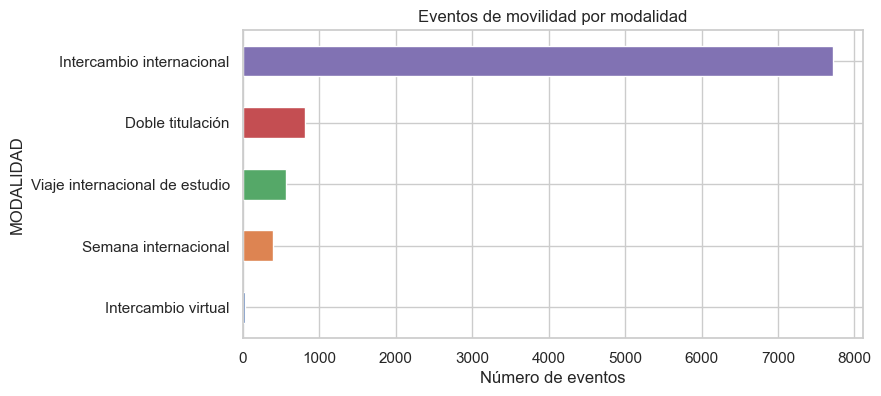

In [4]:
modalidad_counts = eventos['MODALIDAD'].value_counts()
display(modalidad_counts.to_frame('eventos'))

fig, ax = plt.subplots(figsize=(8, 4))
modalidad_counts.sort_values().plot.barh(ax=ax, color=sns.color_palette('deep'))
ax.set_title('Eventos de movilidad por modalidad')
ax.set_xlabel('Número de eventos')
utils.save_fig(fig, 'fig_modalidades_eventos.png')
plt.show()

### Resultado e interpretación
Se identifican **9.526 eventos de movilidad internacional** correspondientes a
**8.067 estudiantes**. La modalidad dominante es el **intercambio internacional**
(cerca del 81% de los eventos), seguido por **doble titulación**, **viaje
internacional de estudio** y **semana internacional**. El **intercambio virtual**
es marginal pero presente (modalidad surgida principalmente durante la pandemia).

**Decisión:** se excluye del foco la modalidad "intercambio nacional" (parámetro
`only_international=True`), ya que no corresponde a internacionalización. La señal
resultante es coherente con las categorías de movilidad que gestiona una Oficina
de Internacionalización.

## 2. Prevención de *data leakage*
Guardamos el primer periodo de movilidad por estudiante: cualquier predictor futuro deberá anclarse a un momento anterior a esta fecha.

In [5]:
part = intl.student_participation(eventos)
print('Resumen de participación por estudiante:')
display(part[['N_EVENTOS_MOVILIDAD']].describe().T)
print('\nDistribución del primer año de movilidad (recientes):')
display(part.groupby('PRIMER_ANIO_MOVILIDAD').size().tail(10).to_frame('estudiantes'))

Resumen de participación por estudiante:


,count,mean,std,min,25%,50%,75%,max
N_EVENTOS_MOVILIDAD,8067.0,1.18086,0.562609,1.0,1.0,1.0,1.0,7.0



Distribución del primer año de movilidad (recientes):


,estudiantes
PRIMER_ANIO_MOVILIDAD,
2017,351
2018,368
2019,397
2020,194
2021,218
2022,460
2023,487
2024,440
2025,499


### Resultado e interpretación
La mayoría de los estudiantes participa **una sola vez** (media de ~1.18 eventos,
mediana 1), con casos de hasta 7 eventos. Guardar `PRIMER_PERIODO_MOVILIDAD`
permite, en la fase de modelamiento (semana 10+), construir predictores usando
**solo** información anterior a ese periodo, respetando la advertencia de la
propuesta sobre fuga de información: una variable registrada después de la
movilidad no puede usarse para predecirla.

## 3. Construcción del dataset analítico
Ejecutamos el pipeline reproducible que integra todas las fuentes a nivel estudiante.

In [6]:
from src import build_dataset
df = build_dataset.build(verbose=True)
print('\nForma del dataset analítico:', df.shape)
df[['CODIGO_ESTUDIANTE', 'NIVEL', 'FACULTAD', 'PGA_ULTIMO', 'SEMESTRE_AVANCE',
    'PARTICIPA', 'MODALIDAD_PRINCIPAL']].head(8)

[1/8] Cargando columna vertebral (informacion_actual)...


      estudiantes (universo): 233,987


[2/8] Extrayendo eventos de movilidad (señal de internacionalización)...


      eventos de movilidad: 9,526 | estudiantes participantes: 8,067


[3/8] Agregando desempeño académico (historial_rendimiento)...


...

[7/8] Integrando todas las fuentes (left join sobre el estudiante)...


[8/8] Guardando dataset analítico (233,987 filas, 44 columnas)...


      -> C:\Users\JUAN DAVID\Documents\UNIANDES\8VO SEMESTRE\PROY GRADO 2026-2\TRAVAIL\PROY-GRADO\data_processed\dataset_analitico_estudiante.parquet


      [validación] clave única: OK | filas: 233,987 | tasa de participación global: 3.43%
      [validación] tasa de participación en pregrado: 4.15%

Forma del dataset analítico: (233987, 44)


,CODIGO_ESTUDIANTE,NIVEL,FACULTAD,PGA_ULTIMO,SEMESTRE_AVANCE,PARTICIPA,MODALIDAD_PRINCIPAL
0,33d0b914c805,Educación continua,CE,NaN,NaN,0,NaN
1,669de3862bbd,Educación continua,CE,NaN,NaN,0,NaN
2,41b0022c9c36,Educación continua,CE,NaN,NaN,0,NaN
3,3a0ad427b990,Magíster,AD,NaN,NaN,0,NaN
4,2fbe85e163a2,Magíster,AD,NaN,NaN,0,NaN
5,5fe8b901fbfc,Educación continua,CE,NaN,NaN,0,NaN
6,9ae53e5eaaf4,Educación continua,CE,NaN,NaN,0,NaN
7,4e8f73a4f6b4,Educación continua,CE,NaN,NaN,0,NaN


### Resultado e interpretación
El pipeline produce un dataset de **233.987 estudiantes × 44 variables**, con la
clave de estudiante única (validación automática superada). Integra: atributos
demográficos e institucionales, desempeño académico agregado (PGA histórico,
créditos, semestres), posición relativa (percentil de PGA), avance (semestre),
pruebas de ingreso (ICFES), clasificación de inglés/matemáticas, progreso de
créditos (CAPP) y la **etiqueta `PARTICIPA`**.

## 4. Tasa de participación y desbalance de clases
Este es un insumo decisivo para la estrategia de modelamiento.

In [7]:
tasa_global = 100 * df['PARTICIPA'].mean()
tasa_preg = 100 * df.loc[df['ES_PREGRADO'], 'PARTICIPA'].mean()
print(f'Tasa de participación global: {tasa_global:.2f}%')
print(f'Tasa de participación en pregrado: {tasa_preg:.2f}%')

tabla_nivel = df.groupby('NIVEL')['PARTICIPA'].agg(['sum', 'count', 'mean'])
tabla_nivel['tasa_%'] = (100 * tabla_nivel['mean']).round(2)
tabla_nivel = tabla_nivel.sort_values('count', ascending=False)
tabla_nivel[['sum', 'count', 'tasa_%']]

Tasa de participación global: 3.43%
Tasa de participación en pregrado: 4.15%


,sum,count,tasa_%
NIVEL,,,
Pregrado,5821,140422,4.15
Magíster,1778,47519,3.74
Especialización,268,24508,1.09
Extensión,57,10253,0.56
Educación continua,52,8645,0.60
Doctorado,51,2169,2.35
Nivelatorio posgrado,7,445,1.57
Sin información,2,23,8.70
INTERMEDIO,0,2,0.00


### Resultado e interpretación
La participación es un fenómeno **minoritario y desbalanceado**: 3.43% global y
**4.15% en pregrado**. El pregrado concentra el mayor volumen de participantes
(5.821) y la tasa más alta entre los niveles con volumen relevante. Esto
confirma dos decisiones:

- **Foco en pregrado** para el análisis y el modelamiento posterior.
- La métrica de evaluación del futuro modelo no podrá ser solo la exactitud
  (un clasificador trivial que prediga "no participa" acertaría ~96%): habrá que
  usar **precision/recall, F1 y PR-AUC**, tal como anticipa la propuesta para
  clases desbalanceadas.

## 5. Tratamiento de valores faltantes en el subconjunto de pregrado
Evaluamos la cobertura real de las variables candidatas antes de decidir imputación.

In [8]:
preg = df[df['ES_PREGRADO']].copy()
feats = ['PGA_ULTIMO', 'PERCENTIL_PGA_PROGRAMA', 'SEMESTRE_AVANCE',
         'ICFES_PUNTAJE_TOTAL', 'ICFES_INGLES', 'NIVEL_INGLES',
         'PCT_CREDITOS_APROBADOS', 'EDAD', 'SEMESTRES_MATRICULADOS']
cobertura = pd.DataFrame({
    'pct_faltante': (100 * preg[feats].isna().mean()).round(1),
    'no_nulos': preg[feats].notna().sum(),
}).sort_values('pct_faltante', ascending=False)
cobertura

,pct_faltante,no_nulos
NIVEL_INGLES,87.8,17135
SEMESTRE_AVANCE,55.0,63228
PERCENTIL_PGA_PROGRAMA,55.0,63228
PGA_ULTIMO,46.4,75238
PCT_CREDITOS_APROBADOS,46.4,75238
SEMESTRES_MATRICULADOS,46.4,75238
ICFES_INGLES,45.2,76955
ICFES_PUNTAJE_TOTAL,45.0,77302
EDAD,0.2,140123


### Resultado e interpretación
En pregrado, las variables presentan faltantes relevantes: `NIVEL_INGLES` ~88%,
el bloque de PGA/avance ~46-55% y el ICFES ~45%. El alto faltante se explica por
la **naturaleza del snapshot**: `informacion_actual` incluye estudiantes muy
antiguos (sin ICFES moderno) o con trayectorias cortas (sin historial de
rendimiento consolidado).

**Decisiones de tratamiento (documentadas):**

- `NIVEL_INGLES` se **descarta** como variable principal por cobertura
  insuficiente (<13%); se conserva solo el puntaje de inglés del ICFES.
- Para las variables de desempeño e ICFES se adoptará, en el modelamiento, una
  estrategia de **imputación por mediana + indicador de faltante** (bandera
  `*_faltante`), evitando descartar estudiantes y haciendo explícito el faltante.
  Esta estrategia es coherente con la literatura sobre datos faltantes citada en
  la propuesta (Little y Rubin). No se imputa en la fase de EDA: aquí se analizan
  los datos observados.
- El tratamiento definitivo se consolidará junto con la construcción de
  predictores anti-*leakage* en la fase de modelamiento (semana 10+).

## 6. Conclusiones y decisiones (semanas 7-8)

- **Señal de internacionalización definida y auditable**: cursos de movilidad en
  `historial_materias` (nombre + código), clasificados por modalidad. 9.526
  eventos / 8.067 estudiantes.
- **Dataset analítico** construido y validado (233.987 × 44), reproducible con
  `python -m src.build_dataset`.
- **Desbalance** confirmado (4.15% en pregrado) → define la estrategia de métricas
  del modelo.
- **Faltantes** caracterizados; reglas de tratamiento definidas y justificadas.
- **Anti-leakage**: se preserva el primer periodo de movilidad por estudiante.

**Siguiente paso:** análisis exploratorio univariado y bivariado (semana 8) y
análisis descriptivo profundo con indicadores (semana 9).